# 03 · Distributions and Relationship with the Target

**Objective:** describe how each variable in the dataset is distributed and how it relates to the
target `is_canceled`, in order to identify which variables are useful for predicting booking
cancellations and which transformations they will need before modelling (encoding, binning, scaling).

**Scope:**
- Includes: variable inventory and data types, class balance of the target, distributions of
  numerical and categorical variables, cancellation rate by variable, and a preliminary selection of
  useful variables, including a check for variables not available at booking time (data leakage).
- Does not include: duplicates, missing and erroneous values (→ `01_cleaning`), or outlier
  detection and treatment (→ `02_outliers`).

**Data:** for now this notebook uses the original CSV (`hotels.csv`, 119,390 bookings × 32 columns).
Once `01_cleaning` produces `data/hotels_clean.csv` (18 Nov), change `csv_path` and re-run the
notebook; the figures quoted in the conclusions will be updated then.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("pandas", pd.__version__, "| seaborn", sns.__version__)

pandas 3.0.6 | seaborn 0.13.2


In [3]:
csv_path = "../data/hotels.csv"   # on 18 Nov change to "../data/hotels_clean.csv"
df = pd.read_csv(csv_path)
df.shape

(119390, 32)

In [4]:
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [5]:
inventory = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_unique": df.nunique(),
    "n_missing": df.isna().sum(),
    "example": df.iloc[0],
})
inventory

,dtype,n_unique,n_missing,example
hotel,str,2,0,Resort Hotel
is_canceled,int64,2,0,0
lead_time,int64,479,0,342
arrival_date_year,int64,3,0,2015
arrival_date_month,str,12,0,July
arrival_date_week_number,int64,53,0,27
arrival_date_day_of_month,int64,31,0,1
stays_in_weekend_nights,int64,17,0,0
stays_in_week_nights,int64,35,0,0
adults,int64,14,0,2


In [6]:
target = "is_canceled"
numerical_continuous = ["adr", "lead_time", "days_in_waiting_list"]
numerical_counts = ["adults", "children", "babies", "previous_cancellations","previous_bookings_not_canceled", "booking_changes", "required_car_parking_spaces", "total_of_special_requests", "stays_in_weekend_nights", "stays_in_week_nights"]
binary = ["is_repeated_guest"]
categorical = ["meal", "hotel", "deposit_type", "reserved_room_type", "assigned_room_type", "customer_type", "market_segment", "distribution_channel", "country"]
id_codes = ["agent", "company"]
date_parts = ["arrival_date_year", "arrival_date_month", "arrival_date_week_number", "arrival_date_day_of_month"]
leakage = ["reservation_status", "reservation_status_date"]

In [7]:
all_columns = [target] + numerical_continuous + numerical_counts + binary + categorical + id_codes + date_parts + leakage

print(len(all_columns), "assigned |", len(df.columns), "in the dataset")
print("Every column assigned exactly once: ", sorted(all_columns) == sorted(df.columns))

32 assigned | 32 in the dataset
Every column assigned exactly once:  True


### Conclusions and actions: variable inventory

**Conclusions**
- The dataset has 119,390 rows × 32 columns. Each row is one booking at one of the two hotels.
- The 32 columns fall into: 1 target, 3 continuous, 10 counts, 1 binary, 9 categorical,
  2 ID codes, 4 arrival-date parts and 2 leakage columns.
- Several stored types do not match their meaning:
  - `is_canceled` and `is_repeated_guest` are stored as `int`, but they are binary (0/1).
  - `agent` and `company` are stored as `float`, but they are ID codes. They are `float` because
    the text `NULL` (which means "no agent / no company", not a missing value) is read as `NaN`.
  - `children` is `float` only because it has 4 missing values.
  - `arrival_date_month` and `reservation_status_date` are stored as text.
- `reservation_status` and `reservation_status_date` are only known after the outcome:
  Canceled (43,017) and No-Show (1,207) correspond exactly to `is_canceled = 1`, and Check-Out
  (75,166) to `is_canceled = 0`. They are data leakage.

**Actions**
- Each group gets its own analysis in the next steps: histograms and boxplots for continuous
  variables, frequency bar charts for counts, and frequency tables plus cancellation rate per
  category for categorical, binary and date variables.
- `arrival_date_month` will be put in calendar order before plotting, since alphabetical order is
  meaningless for months.
- `agent` and `company` will be treated as categories, never averaged. Passed to `01_cleaning`:
  recode `NULL` as "no agent / no company" instead of imputing it, and restore `children` to `int`
  once its missing values are handled.
- `reservation_status` and `reservation_status_date` are excluded as features and documented in
  the README. `booking_changes`, `assigned_room_type` and `days_in_waiting_list` may only be known
  after the booking is made; they are kept for now and reviewed in the leakage check.

In [8]:
counts = df[target].value_counts()
proportions = df[target].value_counts(normalize=True)
pd.DataFrame({"count": counts, "proportion": proportions.round(3)})

,count,proportion
is_canceled,,
0,75166,0.63
1,44224,0.37


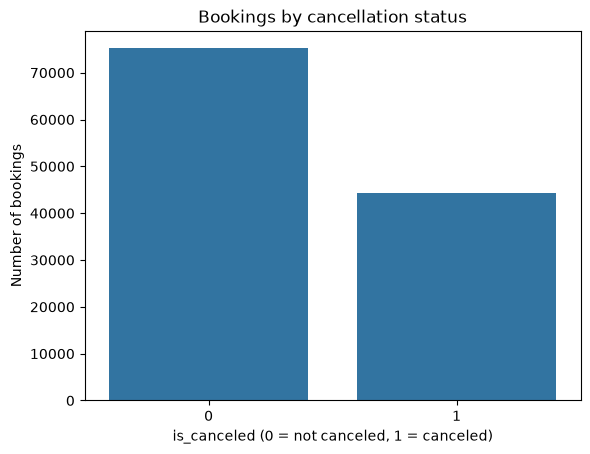

In [9]:
sns.countplot(data=df, x=target)
plt.title("Bookings by cancellation status")
plt.xlabel("is_canceled (0 = not canceled, 1 = canceled)")
plt.ylabel("Number of bookings")
plt.show()

### Conclusions and actions: target

**Conclusions**
- 44,224 of 119,390 bookings (**37%**) **are cancelled** (`is_canceled = 1`) and 75,166 (63%) are not.

The proportion shows that the classes are mildly imbalanced: about one booking in three is cancelled. That is far from a severe case like fraud, where positives can be 1%. A model can learn this without special tricks, but accuracy is still a misleading measure, as question 3 shows.

- A trivial model that always predicts "not canceled" would already reach 63% accuracy while
  detecting no cancellation at all (sensitivity = 0), so **accuracy alone is misleading here**.

So a model with, say, 65% accuracy would barely beat a rule that does nothing. Accuracy misleads with imbalanced classes. The 63% is the baseline any real model has to beat, which is why sensitivity, precision and AUC matter too.

- The **positive class includes 1,207 No-Shows** (2.7% of cancellations). For the hotel, both outcomes
  mean a room that is not occupied as planned, so keeping them together fits the business goal.

With a cancellation or a no-show, the room isn’t occupied as planned. The hotel can’t sell it, unless it overbooks or resells in time. The differences are timing (a no-show is known only on the arrival day) and money (a no-show usually loses the deposit). The hotel’s business problem is anticipating empty rooms, so grouping both makes sense. They’re also a small share: 1,207 is 2.7% of the positives.


**Actions**
- 37% is the reference rate for the rest of the notebook: a group is considered higher risk only if
  its cancellation rate is clearly above it.
- When modelling: use a stratified train/test split so both sets keep the 63/37 proportion, and
  report sensitivity, precision and AUC alongside accuracy, against the 63% baseline.
- README: define the positive class as "cancelled or no-show".